In [1]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models                                   # type: ignore 

from tensorflow.keras.layers import Dropout, Dense, GlobalAveragePooling2D    # type: ignore 
from tensorflow.keras.preprocessing.image import ImageDataGenerator           # type: ignore 

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint # type: ignore

In [2]:
# Train Augmentation Setup (Rescale REMOVED because MobileNet Preprocessing is used below)
train_datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Validation Setup (No Augmentation, No Rescaling)
val_datagen = ImageDataGenerator()

test_datagen = ImageDataGenerator()

In [3]:
# TRAIN GENERATOR:
train_generator = train_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/train', 
    target_size=(224, 224),
    batch_size=32, 
    class_mode='categorical',
    shuffle=True
)

# VALIDATION GENERATOR:
val_generator = val_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/validate',
    target_size=(224, 224), 
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)


num_classes = train_generator.num_classes
print(f"Total classes to detect: {num_classes}")

Found 10450 images belonging to 51 classes.
Found 1761 images belonging to 51 classes.
Total classes to detect: 51


In [4]:
class_names = list(train_generator.class_indices.keys())
print(class_names)

['Aloe_Vera', 'Bird_of_Paradise', 'Black_Sage', 'Bladderpod', 'Blue_Elderberry', 'Blue_Gum_Eucalyptus', 'Bougainvillea', 'CA_Bush_Sunflower', 'California_Buckwheat', 'California_Poppy', 'California_Sagebrush', 'Castor_Bean', 'Ceanothus_CA_Lilac', 'Chalk_Dudleya', 'Coast_Live_Oak', 'Common_Fennel', 'English_Ivy', 'European_Olive', 'Fiddle_Leaf_Fig', 'Flamingo_Flower', 'French_Lavender', 'Golden_Pothos', 'Heartleaf_Philodendron', 'Ice_Plant', 'Indoor_Rose', 'Jacaranda', 'Jade_Plant', 'Joshua_Tree', 'Manzanita', 'Mariposa_Lily', 'Matilija_Poppy', 'Meyer_Lemon', 'Mustard_Plant', 'Our_Lords_Candle', 'Palo_Verde', 'Peace_Lily', 'Poison_Hemlock', 'Prickly_Pear', 'Rosemary', 'Rubber_Plant', 'Snake_Plant', 'Spider_Plant', 'Sticky_Monkey-flower', 'Stinknet', 'Swiss_Cheese_Plant', 'Toyon', 'Tree_Tobacco', 'Western_Poison_Oak', 'Western_Sycamore', 'Wild_Radish', 'ZZ_Plant']


In [5]:
# 3. MODEL ARCHITECTURE
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = True

# Level 50 Deep Unfreezing
fine_tune_at = 50 
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

# MobileNetV2 expects raw pixels [0, 255] and converts them to [-1, 1] internally:
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=True) 

x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x) 

outputs = layers.Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

In [6]:
# Ensure models directory exists
os.makedirs("04_Models", exist_ok=True)

In [7]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 51)             │        65,331 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,328,435 (8.88 MB)

 Trainable params: 2,242,483 (8.55 MB)

 Non-trainable params: 85,952 (335.75 KB)

In [8]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.000005),    # Ultra-small LR for V5 Deep Learning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
print("Model compilation done!!")


# STOP training if accuracy don't improve
early_stop = EarlyStopping(
    monitor='val_accuracy', 
    patience=5, 
    restore_best_weights=True
)

# If accuracy stucks reduce the LR
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=3, 
    min_lr=1e-7
)

# Save the best model
checkpoint = ModelCheckpoint(
    "04_Models/caliplant_v5.keras", 
    monitor='val_accuracy', 
    save_best_only=True
)

print(" Callbacks (EarlyStop, ReduceLR, Checkpoint) configured successfully!")



history = model.fit(
    train_generator,
    epochs= 40,  # Callback checks handled by EarlyStopping automatically
    validation_data=val_generator,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

print("\n V5 MobileNetV2 Training Complete! Best version securely saved in '04_Models/caliplant_v5.keras'.")


Model compilation done!!
 Callbacks (EarlyStop, ReduceLR, Checkpoint) configured successfully!
Epoch 1/40
285/327 ━━━━━━━━━━━━━━━━━━━━ 34s 817ms/step - accuracy: 0.0282 - loss: 5.1544

c:\Users\sanch\Documents\Git_hub\CaliPlant_AI\ai_env\Lib\site-packages\PIL\Image.py:1137: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


327/327 ━━━━━━━━━━━━━━━━━━━━ 305s 896ms/step - accuracy: 0.0384 - loss: 4.9574 - val_accuracy: 0.0505 - val_loss: 4.3995 - learning_rate: 5.0000e-06
Epoch 2/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 268s 821ms/step - accuracy: 0.0855 - loss: 4.2326 - val_accuracy: 0.1323 - val_loss: 3.7428 - learning_rate: 5.0000e-06
Epoch 3/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 267s 816ms/step - accuracy: 0.1734 - loss: 3.6681 - val_accuracy: 0.2311 - val_loss: 3.1879 - learning_rate: 5.0000e-06
Epoch 4/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 279s 853ms/step - accuracy: 0.2356 - loss: 3.1972 - val_accuracy: 0.3123 - val_loss: 2.7738 - learning_rate: 5.0000e-06
Epoch 5/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 287s 876ms/step - accuracy: 0.3132 - loss: 2.8344 - val_accuracy: 0.3822 - val_loss: 2.4724 - learning_rate: 5.0000e-06
Epoch 6/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 263s 803ms/step - accuracy: 0.3710 - loss: 2.5320 - val_accuracy: 0.4378 - val_loss: 2.2483 - learning_rate: 5.0000e-06
Epoch 7/40
327/327 ━━━━━━━━━━━━━━━━━━━━ 291s 890ms/

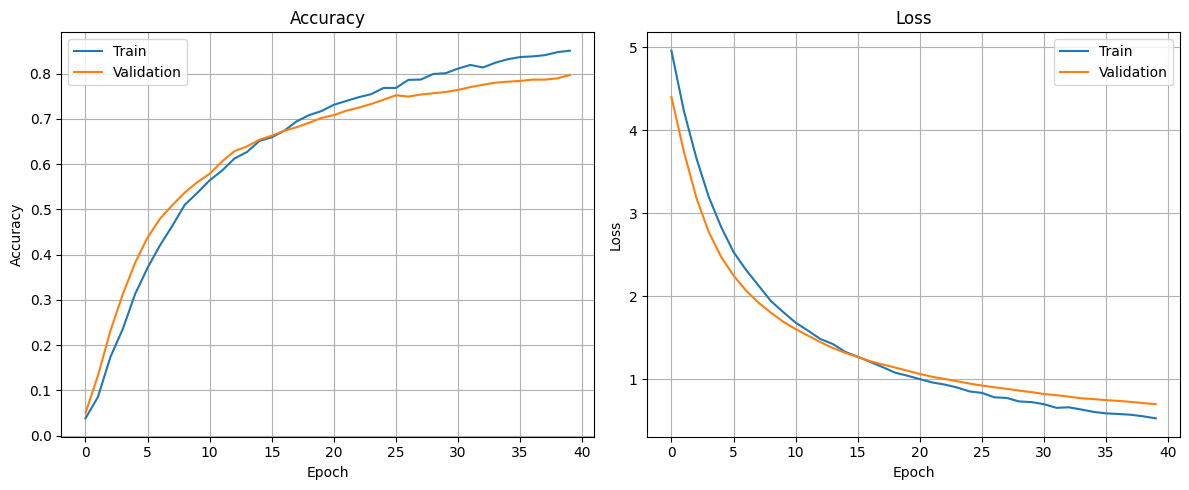

In [9]:
plt.figure(figsize=(12,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
# SECTION 5: TEST GENERATOR (For evaluation)
test_generator = test_datagen.flow_from_directory(
    'C:/Users/sanch/Documents/Git_hub/CaliPlant_AI/03_Data/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # CRITICAL: Isko False hi rakhna hai evaluation ke liye
)

Found 868 images belonging to 51 classes.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Evaluating model on test dataset...")

# 1. Test images par predictions nikalna
predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)

Evaluating model on test dataset...
28/28 ━━━━━━━━━━━━━━━━━━━━ 14s 475ms/step


In [12]:
# 2. True (Original) labels nikalna
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

In [13]:
#  SECTION A: OVERALL TEST ACCURACY :Pura dataset par overall evaluation
test_loss, test_acc = model.evaluate(test_generator, verbose=0)
print("\n" + "="*50)
print(f"Final Test Accuracy: {test_acc*100:.2f}%")
print(f"Final Test Loss:     {test_loss:.4f}")
print("="*50 + "\n")


Final Test Accuracy: 78.92%
Final Test Loss:     0.7992

